<a href="https://colab.research.google.com/github/OrastaRakhmatullayeva/9-Digit-Recognition/blob/main/Random_forest_Telco_customer_churn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Telco Customer Churn Prediction

I wanted to understand why customers leave a telecom company and whether their account and service details can help identify customers at risk of leaving.

This project compares Logistic Regression and Random Forest, with a focus on identifying churn rather than accuracy alone.

**Dataset:** [Telco Customer Churn (Kaggle)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) — the original dataset contains 7,043 customers and 21 columns.

## 1. Imports and data loading
Download `WA_Fn-UseC_-Telco-Customer-Churn.csv` from the dataset link and upload it to the Colab Files panel before running the notebook. The same file can be placed next to the notebook locally.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

sns.set_theme(style="whitegrid")

In [3]:
path = Path("WA_Fn-UseC_-Telco-Customer-Churn.csv")
if not path.exists():
    path = Path("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df = pd.read_csv(path)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Data cleaning
`TotalCharges` looks numeric, but blank strings can make pandas read it as text. I convert it to a number and check missing values again. For new customers with zero tenure, missing total charges can reasonably be set to zero. Any other missing values are handled inside the training pipeline.

In [4]:
df.info()
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
mask = df["TotalCharges"].isna() & df["tenure"].eq(0)
df.loc[mask, "TotalCharges"] = 0
print(df.isna().sum())
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
df = df.dropna(subset=["Churn"])
df["Churn"] = df["Churn"].astype(int)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 3. Train-test split
I remove customer IDs because they identify individuals rather than describe their behavior. The stratified split preserves the churn ratio in both sets. I keep the test set separate from model tuning.

In [5]:
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))
print("Input features:", X.shape[1])

Training samples: 5634
Test samples: 1409
Input features: 19


## 4. Exploratory data analysis
I use the training set to explore churn patterns. The class distribution helps explain why accuracy alone may be misleading.

Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


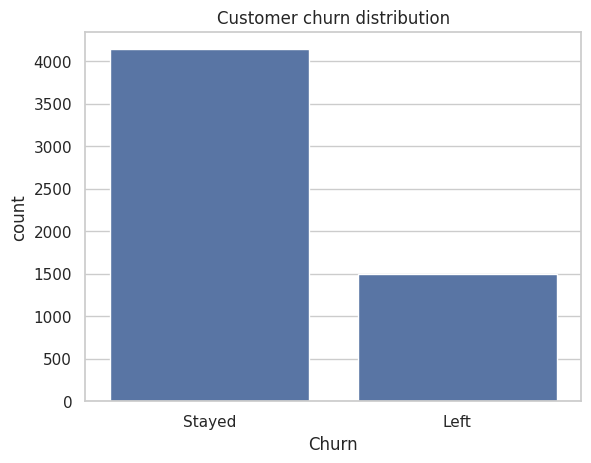

In [6]:
train_df = X_train.copy()
train_df["Churn"] = y_train
print(train_df["Churn"].value_counts(normalize=True).mul(100).round(2))
sns.countplot(data=train_df, x="Churn")
plt.xticks([0, 1], ["Stayed", "Left"])
plt.title("Customer churn distribution")
plt.show()

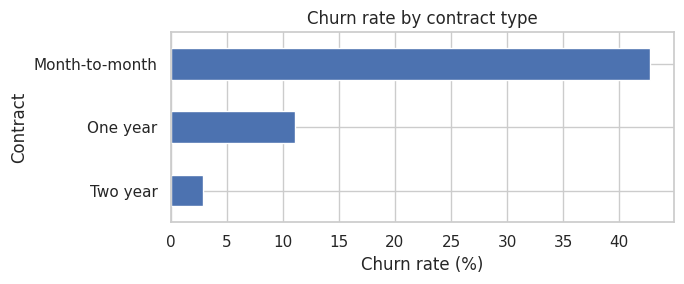

,Churn
Contract,
Two year,2.87
One year,11.08
Month-to-month,42.75


In [7]:
contract_rates = train_df.groupby("Contract")["Churn"].mean().mul(100).sort_values()
contract_rates.plot.barh(figsize=(7, 3))
plt.xlabel("Churn rate (%)")
plt.title("Churn rate by contract type")
plt.tight_layout()
plt.show()
display(contract_rates.round(2))

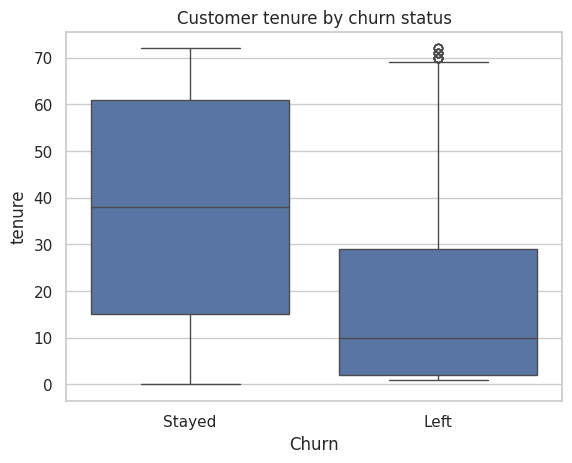

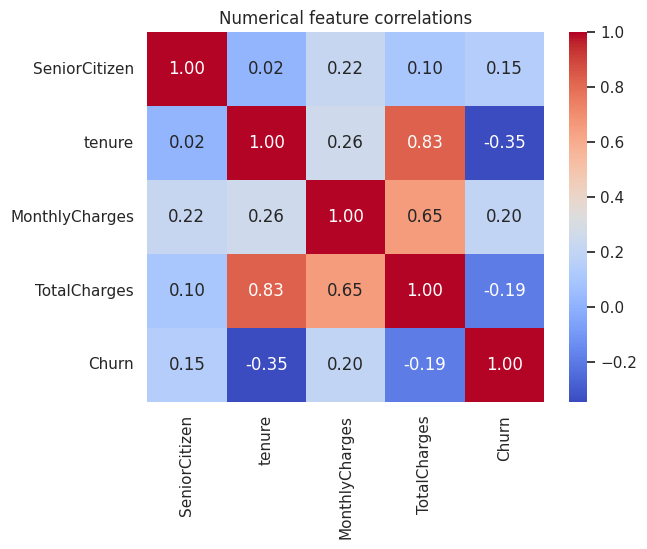

In [8]:
sns.boxplot(data=train_df, x="Churn", y="tenure")
plt.xticks([0, 1], ["Stayed", "Left"])
plt.title("Customer tenure by churn status")
plt.show()
sns.heatmap(train_df.select_dtypes(include="number").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Numerical feature correlations")
plt.show()

## 5. Preprocessing
I keep the original ColumnTransformer and Pipeline approach. Numerical features are imputed and scaled, while categorical features are encoded. The pipeline learns these transformations from training data only, including during cross-validation.

In [9]:
num = X_train.select_dtypes(include="number").columns
cat = X_train.select_dtypes(exclude="number").columns

numeric = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric, num),
    ("cat", categorical, cat)
])

## 6. Baseline and Random Forest
Logistic Regression is a simple baseline. I also train a default Random Forest and a balanced version to see whether giving more weight to churn customers improves recall.

In [10]:
models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(random_state=42, n_jobs=-1))
    ]),
    "Balanced Random Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1))
    ])
}
for model in models.values():
    model.fit(X_train, y_train)

## 7. Hyperparameter tuning
I use a smaller grid than in my original experiment to keep training practical in Colab. Five-fold stratified cross-validation selects parameters using F1, which balances precision and recall. The test set is not used for tuning.

In [11]:
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10],
    "classifier__min_samples_leaf": [1, 4],
    "classifier__class_weight": [None, "balanced"]
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search_model = clone(models["Random Forest"])
search_model.set_params(classifier__n_jobs=1)
grid_search = GridSearchCV(search_model, param_grid, cv=cv, scoring="f1", n_jobs=2)
grid_search.fit(X_train, y_train)
models["Tuned Random Forest"] = grid_search.best_estimator_
print("Best parameters:", grid_search.best_params_)
print(f"Best CV F1: {grid_search.best_score_:.4f}")

Best parameters: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 4, 'classifier__n_estimators': 200}
Best CV F1: 0.6311


## 8. Model comparison
All four models are evaluated on the same held-out test set. Recall measures how many churn customers are found, precision measures how many flagged customers actually churn, and ROC-AUC measures ranking ability across thresholds.

In [12]:
results = []
for name, model in models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba)
    })
comparison = pd.DataFrame(results).set_index("Model")
display(comparison.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8421
Random Forest,0.7864,0.6254,0.4866,0.5474,0.8185
Balanced Random Forest,0.7807,0.6102,0.4813,0.5381,0.8194
Tuned Random Forest,0.7651,0.5416,0.7487,0.6285,0.8410


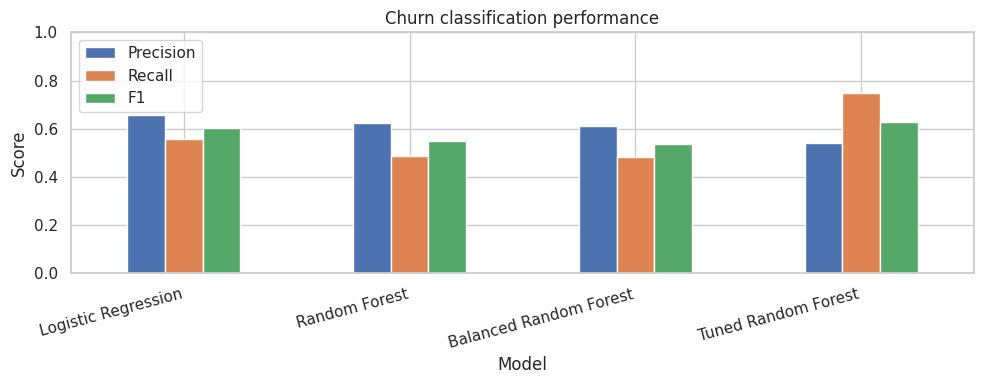

In [13]:
comparison[["Precision", "Recall", "F1"]].plot.bar(figsize=(10, 4))
plt.ylim(0, 1)
plt.title("Churn classification performance")
plt.ylabel("Score")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

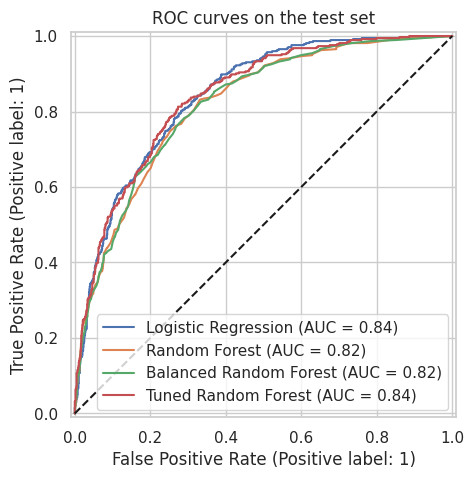

In [14]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--")
ax.set_title("ROC curves on the test set")
plt.show()

### Tuned Random Forest: error analysis
The confusion matrix shows missed churn customers (false negatives) and customers incorrectly flagged as at risk (false positives). I inspect the tuned model as the main Random Forest experiment, without assuming it outperforms every baseline.

              precision    recall  f1-score   support

      Stayed       0.89      0.77      0.83      1035
     Churned       0.54      0.75      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409



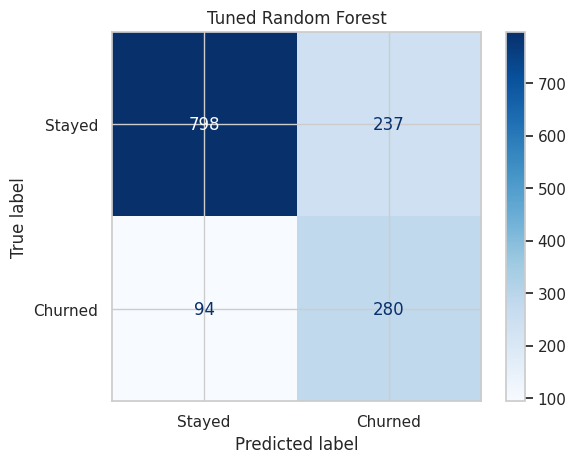

In [15]:
final_model = grid_search.best_estimator_
y_pred = final_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Stayed", "Churned"], cmap="Blues")
plt.title("Tuned Random Forest")
plt.show()

## 9. Feature importance
Random Forest feature importance helps describe which encoded features the model relies on. These values do not establish that a feature causes churn.

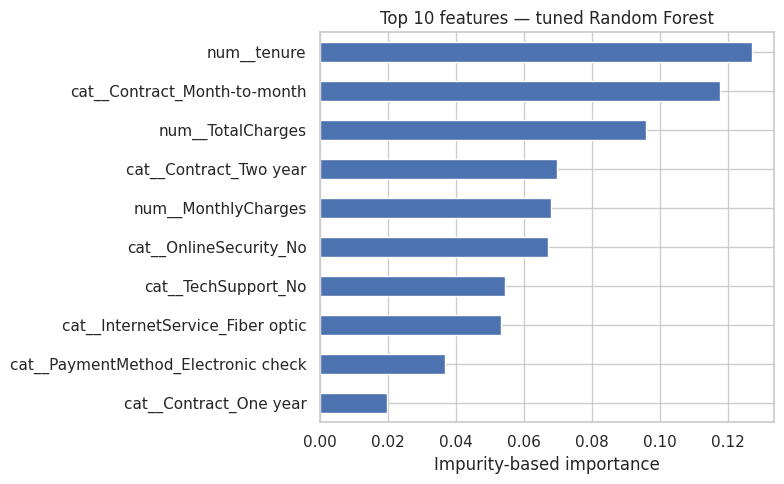

In [16]:
feature_names = final_model.named_steps["preprocessor"].get_feature_names_out()
importance = pd.Series(final_model.named_steps["classifier"].feature_importances_, index=feature_names)
importance.nlargest(10).sort_values().plot.barh(figsize=(8, 5))
plt.xlabel("Impurity-based importance")
plt.title("Top 10 features — tuned Random Forest")
plt.tight_layout()
plt.show()

## 10. Business insights and conclusion
The results below summarize the experiment using the actual model outputs. A telecom company could use churn scores to prioritize retention outreach, but the cost of missed customers should be weighed against unnecessary offers. A future experiment could tune the decision threshold on validation data and check performance on a later customer cohort.

In [17]:
print("Training-set churn rate by contract type:")
print(contract_rates.round(2).to_string())
print("\nTest results for the tuned Random Forest:")
print(comparison.loc["Tuned Random Forest"].round(4).to_string())
print("\nMissed churn customers:", ((y_test == 1) & (y_pred == 0)).sum())
print("Incorrectly flagged customers:", ((y_test == 0) & (y_pred == 1)).sum())

Training-set churn rate by contract type:
Contract
Two year           2.87
One year          11.08
Month-to-month    42.75

Test results for the tuned Random Forest:
Accuracy     0.7651
Precision    0.5416
Recall       0.7487
F1           0.6285
ROC-AUC      0.8410

Missed churn customers: 94
Incorrectly flagged customers: 237


**Limitations:** This is an offline classification experiment using a public dataset. The observed relationships are not causal, and the model has not been validated on future customer cohorts. The comparison is descriptive; a production model would require further validation and a business-specific decision threshold.